# 2.2.3. Bài tập thực hành 1 - SVM trên dữ liệu tiểu đường

Đề yêu cầu xây SVM cho dữ liệu tiểu đường. Sử dụng file diabetes_prediction_dataset.csv đã cung cấp (100.000 dòng), nhãn diabetes 0/1. Không dùng schema Pima vì các cột thực tế khác.

**Lựa chọn mô hình:** dùng **LinearSVC**, một triển khai SVM tuyến tính, để huấn luyện trên toàn bộ dữ liệu sau làm sạch. SVC kernel có chi phí tăng nhanh theo số mẫu; LinearSVC phù hợp hơn cho kích thước này. Bài mẫu Iris/Digits và bài động vật minh họa SVC với kernel phi tuyến. Không gọi LinearSVC là SVM kernel RBF và không lấy mẫu giảm dữ liệu để chấm bài này.

## Nhiệm vụ 1. Nạp, khảo sát và chuẩn bị dữ liệu

### Bước 1. Import và đọc CSV

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import svm, datasets
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 101
# Bao loi neu bo giai chua hoi tu, tranh su dung ket qua huan luyen dang do.
warnings.filterwarnings('error', category=ConvergenceWarning)


lab_candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    lab_candidates.extend([parent, parent / 'Lab05' / '2.2. Giai_Thuat2'])
# Duong dan du an duoc chi dinh; dung khi mo ban notebook tu thu muc outputs.
lab_candidates.append(Path(r'D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2'))
LAB_DIR = next((p for p in lab_candidates if (p / 'data' / 'Iris.csv').is_file()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Chua tim thay thu muc data cua Lab05/2.2. Giai_Thuat2.')
DATA_DIR = LAB_DIR / 'data'
print('Thu muc du lieu:', DATA_DIR)

Thu muc du lieu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\data


Ban dau: (100000, 9) | Dong trung: 3854


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


,dtype,missing
gender,object,0
age,float64,0
hypertension,int64,0
heart_disease,int64,0
smoking_history,object,0
bmi,float64,0
HbA1c_level,float64,0
blood_glucose_level,int64,0
diabetes,int64,0


Sau lam sach: (96146, 9)


,count
diabetes,
0,87664
1,8482


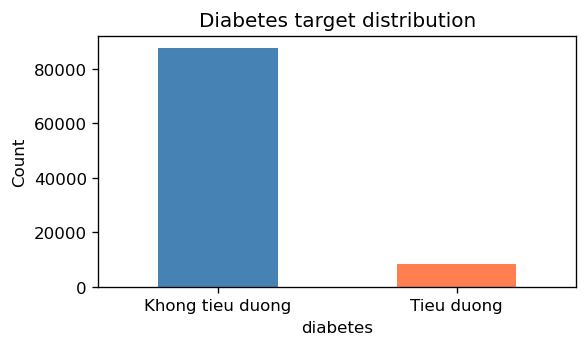

In [2]:
raw_df=pd.read_csv(DATA_DIR/'diabetes_prediction_dataset.csv')
numeric_features=['age','hypertension','heart_disease','bmi','HbA1c_level','blood_glucose_level']
categorical_features=['gender','smoking_history']
feature_columns=numeric_features+categorical_features
TARGET='diabetes'
CLASS_NAMES=['Khong tieu duong','Tieu duong']
RESULT_SLUG='SVM_TieuDuong'
SCORING='roc_auc'
assert set(feature_columns+[TARGET]).issubset(raw_df.columns)
assert not raw_df[TARGET].isna().any() and set(raw_df[TARGET].unique())=={0,1}
print('Ban dau:',raw_df.shape,'| Dong trung:',int(raw_df.duplicated().sum()))
display(raw_df.head())
display(pd.DataFrame({'dtype':raw_df.dtypes.astype(str),'missing':raw_df.isna().sum()}))
df=raw_df.drop_duplicates().reset_index(drop=True)
X=df[feature_columns].copy()
y=df[TARGET].astype(int).copy()
print('Sau lam sach:',df.shape)
display(y.value_counts().to_frame('count'))
fig,ax=plt.subplots(figsize=(5,3))
y.value_counts().sort_index().plot.bar(ax=ax,rot=0,color=['steelblue','coral'])
ax.set_xticklabels(CLASS_NAMES)
ax.set(title='Diabetes target distribution',ylabel='Count')
plt.tight_layout()
plt.show()

### Bước 2. Chia train/test và xây Pipeline

Loại dòng trùng hoàn toàn trước khi chia; dùng 80:20 có stratify. Không tự đổi mọi số 0 thành thiếu: hypertension/heart_disease bằng 0 là hợp lệ. Nhóm smoking_history=No Info được giữ như nhóm chưa có thông tin.

Biến số: SimpleImputer(median) → StandardScaler. Biến chữ: SimpleImputer(most_frequent) → OneHotEncoder(handle_unknown=ignore). Chỉ fit các bước này trên train của mỗi fold. LinearSVC(dual=False) phù hợp khi số mẫu lớn hơn số đặc trưng; tăng max_iter và báo lỗi nếu chưa hội tụ.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).sort_index())
cv_splitter = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

Train: (76916, 8) | Test: (19230, 8)


,train,test
diabetes,,
0,70130,17534
1,6786,1696


In [4]:
numeric_transformer=Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())])
categorical_transformer=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=True))
])
preprocessor=ColumnTransformer([
    ('num',numeric_transformer,numeric_features),
    ('cat',categorical_transformer,categorical_features)
],sparse_threshold=1.0)
baseline=Pipeline([
    ('preprocess',preprocessor),
    ('svc',svm.LinearSVC(C=1,dual=False,max_iter=20000,tol=1e-4,random_state=RANDOM_STATE))
])

t0 = perf_counter()
baseline.fit(X_train, y_train)
print('Train accuracy (baseline):', round(baseline.score(X_train, y_train), 4))
print('Thoi gian fit baseline:', round(perf_counter() - t0, 2), 'giay')

Train accuracy (baseline): 0.9593
Thoi gian fit baseline: 0.2 giay


## Nhiệm vụ 2. Tìm siêu tham số C và trọng số lớp

Thử C theo thang log và class_weight=None hoặc balanced. Dùng ROC AUC từ decision_function để chọn cấu hình trên 4-fold CV của train. Không bật probability hay coi điểm quyết định là xác suất. Tất cả fold và bước refit đều dùng toàn bộ phần train tương ứng, không giảm số mẫu.

Scoring: roc_auc
Baseline mean CV: 0.9606
Tham so tot nhat: {'svc__C': 10, 'svc__class_weight': 'balanced'}
Mean CV tot nhat: 0.9615
Thoi gian tim kiem: 8.16 giay


,params,mean_train_score,mean_test_score,std_test_score,mean_fit_time
7,"{'svc__C': 10, 'svc__class_weight': 'balanced'}",0.961671,0.961538,0.000567,0.403824
5,"{'svc__C': 1, 'svc__class_weight': 'balanced'}",0.961670,0.961535,0.000565,0.107527
3,"{'svc__C': 0.1, 'svc__class_weight': 'balanced'}",0.961666,0.961532,0.000562,0.096738
1,"{'svc__C': 0.01, 'svc__class_weight': 'balanced'}",0.961663,0.961530,0.000562,0.098221
6,"{'svc__C': 10, 'svc__class_weight': None}",0.960716,0.960630,0.000637,0.144298
4,"{'svc__C': 1, 'svc__class_weight': None}",0.960714,0.960628,0.000636,0.099490
2,"{'svc__C': 0.1, 'svc__class_weight': None}",0.960710,0.960624,0.000635,0.092278
0,"{'svc__C': 0.01, 'svc__class_weight': None}",0.960707,0.960623,0.000635,0.101277


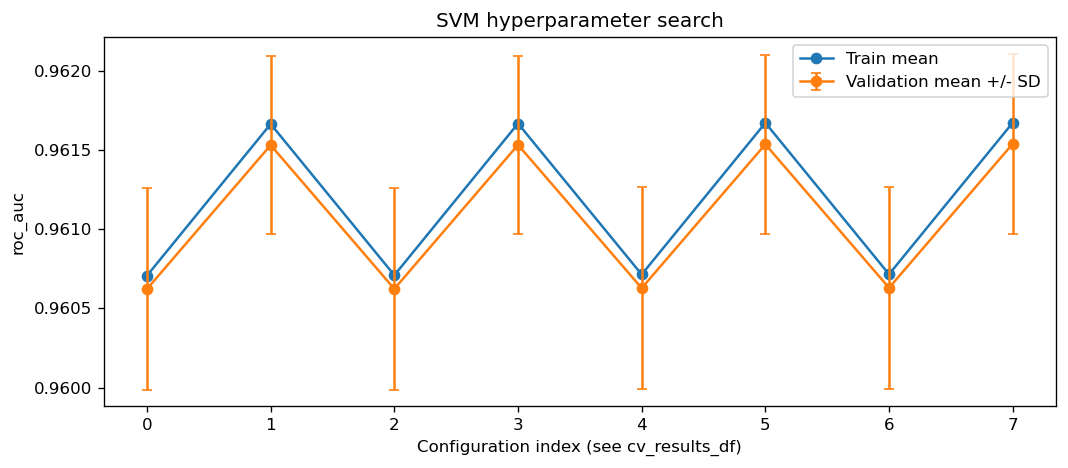

In [5]:
param_grid={'svc__C':[0.01,0.1,1,10],'svc__class_weight':[None,'balanced']}

# Khong dung test de chon kernel hay tham so.
t0 = perf_counter()
baseline_cv_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv_splitter, scoring=SCORING, n_jobs=1, error_score='raise'
)
search = GridSearchCV(
    clone(baseline), param_grid=param_grid, scoring=SCORING, cv=cv_splitter,
    refit=True, return_train_score=True, error_score='raise', n_jobs=1
)
search.fit(X_train, y_train)
best_svm = search.best_estimator_
cv_results_df = pd.DataFrame(search.cv_results_)
print('Scoring:', SCORING)
print('Baseline mean CV:', round(baseline_cv_scores.mean(), 4))
print('Tham so tot nhat:', search.best_params_)
print('Mean CV tot nhat:', round(search.best_score_, 4))
print('Thoi gian tim kiem:', round(perf_counter()-t0, 2), 'giay')
display(cv_results_df[['params', 'mean_train_score', 'mean_test_score',
                       'std_test_score', 'mean_fit_time']].sort_values('mean_test_score', ascending=False).head(12))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(len(cv_results_df)), cv_results_df['mean_train_score'], 'o-', label='Train mean')
ax.errorbar(np.arange(len(cv_results_df)), cv_results_df['mean_test_score'],
            yerr=cv_results_df['std_test_score'], fmt='o-', capsize=3, label='Validation mean +/- SD')
ax.set(xlabel='Configuration index (see cv_results_df)', ylabel=SCORING, title='SVM hyperparameter search')
ax.legend()
plt.tight_layout()
plt.show()

## Nhiệm vụ 3. Đánh giá mô hình trên test

Ngoài accuracy, xem balanced accuracy, macro-F1, recall/precision của lớp ít mẫu, ROC và precision-recall. Lớp 1 ít hơn nên accuracy cao của mô hình luôn đoán 0 không chứng minh khả năng tìm lớp 1. Không điều chỉnh lại C, trọng số hoặc ngưỡng bằng test.


SVM baseline
                  precision    recall  f1-score   support

Khong tieu duong       0.96      0.99      0.98     17534
      Tieu duong       0.89      0.62      0.73      1696

        accuracy                           0.96     19230
       macro avg       0.93      0.81      0.85     19230
    weighted avg       0.96      0.96      0.96     19230




SVM tuned
                  precision    recall  f1-score   support

Khong tieu duong       0.99      0.89      0.93     17534
      Tieu duong       0.43      0.89      0.58      1696

        accuracy                           0.89     19230
       macro avg       0.71      0.89      0.76     19230
    weighted avg       0.94      0.89      0.90     19230



,Train accuracy,CV score,Test accuracy,Test balanced accuracy,Test precision macro,Test recall macro,Test F1 macro,Test ROC AUC (class 1),Minority label,Minority precision,Minority recall,Minority average precision
Model,,,,,,,,,,,,
SVM baseline,0.9593,0.9606,0.9598,0.8067,0.9272,0.8067,0.8549,0.9622,1,0.8901,0.6209,0.8216
SVM tuned,0.8863,0.9615,0.8854,0.8863,0.7078,0.8863,0.7555,0.9633,1,0.4278,0.8874,0.8209


Accuracy neu luon doan lop pho bien: 0.9118


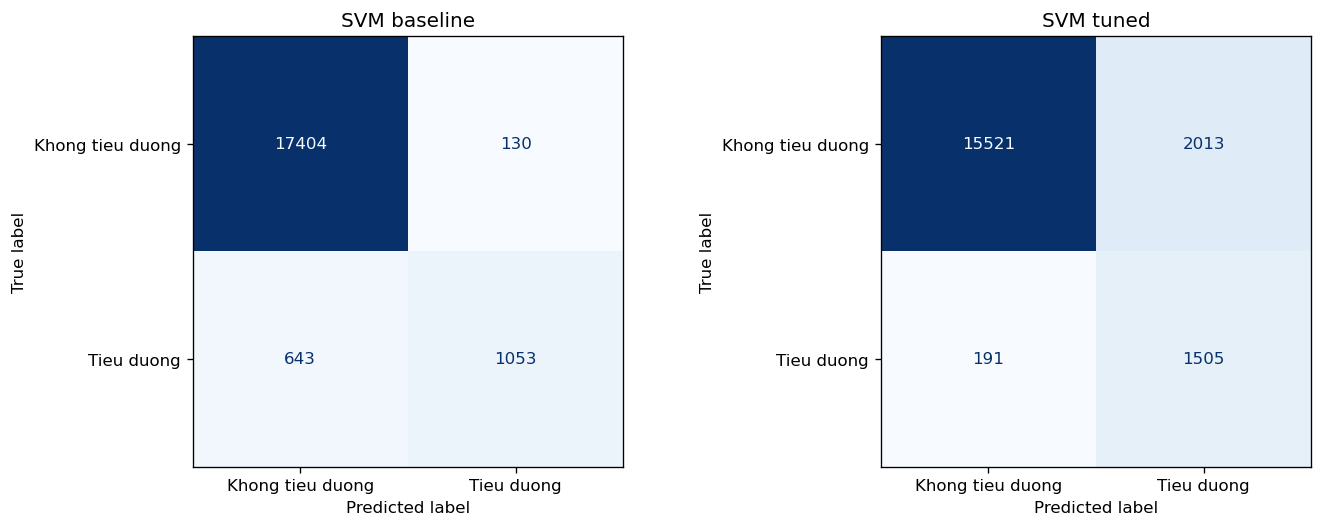

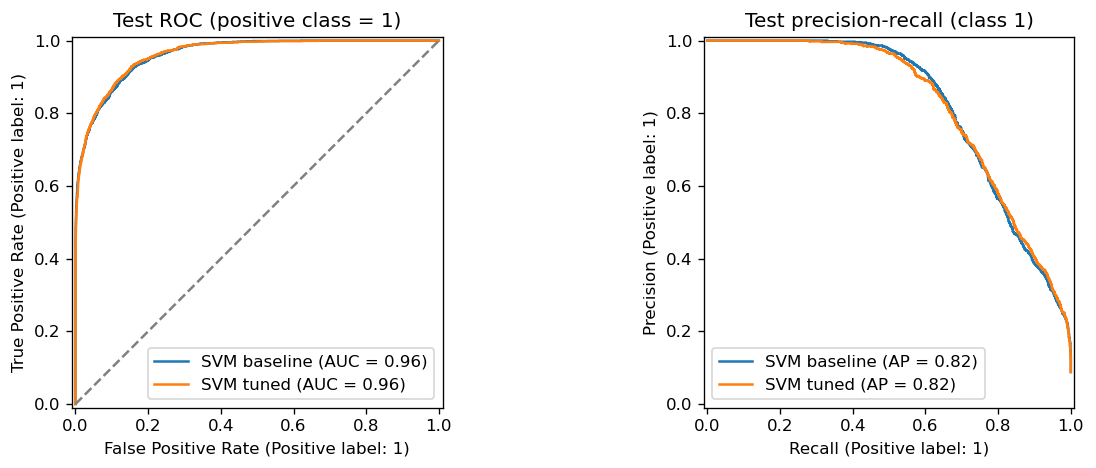

In [6]:
# Danh gia mot lan sau khi chot cau hinh bang CV.
models = {'SVM baseline': baseline, 'SVM tuned': best_svm}
cv_scores = {'SVM baseline': baseline_cv_scores.mean(), 'SVM tuned': search.best_score_}
labels = sorted(pd.unique(y))
is_binary = len(labels) == 2
minority_label = y_train.value_counts().idxmin() if is_binary else None
records, predictions, decision_scores = [], {}, {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {
        'Model': name, 'Train accuracy': model.score(X_train, y_train),
        'CV score': cv_scores[name], 'Test accuracy': accuracy_score(y_test, pred),
        'Test balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Test precision macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'Test recall macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'Test F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)
    }
    if is_binary:
        scores = model.decision_function(X_test)
        decision_scores[name] = scores
        minority_scores = scores if minority_label == model.classes_[1] else -scores
        row['Test ROC AUC (class 1)'] = roc_auc_score(y_test, scores)
        row['Minority label'] = minority_label
        row['Minority precision'] = precision_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority recall'] = recall_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority average precision'] = average_precision_score((y_test==minority_label).astype(int), minority_scores)
    records.append(row)
    print('\n' + name)
    print(classification_report(y_test, pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))

comparison_df = pd.DataFrame(records).set_index('Model')
display(comparison_df.round(4))
majority_baseline = y_test.value_counts(normalize=True).max()
print('Accuracy neu luon doan lop pho bien:', round(majority_baseline, 4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5 if len(labels)<=3 else 5))
for ax, name in zip(axs, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=labels, display_labels=CLASS_NAMES,
        cmap='Blues', colorbar=False, ax=ax, xticks_rotation=45 if len(labels)==3 else 0
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

if is_binary:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, model in models.items():
        scores = decision_scores[name]
        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
        minority_scores = scores if minority_label==model.classes_[1] else -scores
        PrecisionRecallDisplay.from_predictions(
            (y_test==minority_label).astype(int), minority_scores, name=name, ax=axes[1]
        )
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set_title('Test ROC (positive class = 1)')
    axes[1].set_title(f'Test precision-recall (class {minority_label})')
    plt.tight_layout()
    plt.show()

## Nhận xét và lưu kết quả

SVM tuyến tính có thể chưa biểu diễn đủ quan hệ phi tuyến. Việc tăng C không tự tạo kernel phi tuyến. Nếu mở rộng sau bài này, có thể so sánh mô hình kernel hoặc xấp xỉ kernel bằng CV, với chi phí tính toán được báo cáo rõ.

In [7]:
best_row = cv_results_df.loc[search.best_index_]
gap = float(best_row['mean_train_score'] - best_row['mean_test_score'])
tuned = comparison_df.loc['SVM tuned']
acc = tuned['Test accuracy']
f1 = tuned['Test F1 macro']
balanced_acc = tuned['Test balanced accuracy']
notes = '\n\n'.join([
    '### Nhận xét kết quả',
    f'- Train **{len(X_train):,} mẫu**, test **{len(X_test):,} mẫu**. Siêu tham số được chọn bằng **{SCORING}**, 4-fold CV trên train.',
    f'- Tham số chọn trong lưới: **{search.best_params_}**. Điểm CV **{search.best_score_:.4f}**; chênh lệch train - validation tại cấu hình này **{gap:.4f}**.',
    f'- SVM sau tìm kiếm đạt test accuracy **{acc:.4f}**, balanced accuracy **{balanced_acc:.4f}**, F1-macro **{f1:.4f}**.',
    f'- Nếu luôn đoán lớp phổ biến, accuracy là **{majority_baseline:.4f}**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.',
    '- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.',
    '- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.'
])
if is_binary:
    minority_count = int((y_test==minority_label).sum())
    precision_minority = tuned['Minority precision']
    recall_minority = tuned['Minority recall']
    notes += f'\n\n- Lớp ít mẫu là **{minority_label}**, có **{minority_count} mẫu test**. Precision **{precision_minority:.4f}**, recall **{recall_minority:.4f}**.'
display(Markdown(notes))

RESULTS_DIR = LAB_DIR / 'ket_qua' / RESULT_SLUG
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(RESULTS_DIR/'so_sanh_mo_hinh.csv', encoding='utf-8-sig')
cv_results_df.to_csv(RESULTS_DIR/'cv_results.csv', index=False, encoding='utf-8-sig')
prediction_table = pd.DataFrame({'row_index':X_test.index, 'actual':y_test.to_numpy(),
    'baseline_prediction':predictions['SVM baseline'], 'tuned_prediction':predictions['SVM tuned']})
if is_binary:
    prediction_table['baseline_score']=decision_scores['SVM baseline']
    prediction_table['tuned_score']=decision_scores['SVM tuned']
prediction_table.to_csv(RESULTS_DIR/'du_doan_test.csv',index=False,encoding='utf-8-sig')
(RESULTS_DIR/'nhan_xet.md').write_text(notes,encoding='utf-8')
print('Ket qua da luu:',RESULTS_DIR)

### Nhận xét kết quả

- Train **76,916 mẫu**, test **19,230 mẫu**. Siêu tham số được chọn bằng **roc_auc**, 4-fold CV trên train.

- Tham số chọn trong lưới: **{'svc__C': 10, 'svc__class_weight': 'balanced'}**. Điểm CV **0.9615**; chênh lệch train - validation tại cấu hình này **0.0001**.

- SVM sau tìm kiếm đạt test accuracy **0.8854**, balanced accuracy **0.8863**, F1-macro **0.7555**.

- Nếu luôn đoán lớp phổ biến, accuracy là **0.9118**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.

- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.

- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.

- Lớp ít mẫu là **1**, có **1696 mẫu test**. Precision **0.4278**, recall **0.8874**.

Ket qua da luu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\ket_qua\SVM_TieuDuong


### Diễn giải sự đánh đổi của trọng số lớp

Theo ROC AUC trên CV, lưới chọn LinearSVC(C=10, class_weight=balanced). Trên test, recall lớp 1 tăng từ 62,09% của baseline lên 88,74%, nhưng precision giảm từ 89,01% xuống 42,78%; accuracy cũng giảm từ 95,98% xuống 88,54%. Mức tăng AUC nhỏ không đồng nghĩa mô hình tốt hơn ở mọi chỉ số hoặc ở ngưỡng quyết định mặc định. Báo cáo cả hai cấu hình để thể hiện rõ sự đánh đổi, giữ nguyên quy tắc chọn đã đặt trước khi xem test.

## Tài liệu kỹ thuật

- [Scikit-learn - SVM](https://scikit-learn.org/1.7/modules/svm.html)
- [SVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html)
- [LinearSVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.LinearSVC.html)
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html)